# EDA on the training months (modelling plan, Phase 1)

This notebook looks at the data a model is allowed to see, and nothing else. It reads months **0–4** (the training
set) through `amldata.public()` and `amldata.labels(profile=True)`. Month 5 is the calibration set and is not
examined, so nothing here can tune the calibration step; test months 6–7 cannot be read at all.

It is different from `src/sim/eda`, which checks the simulator and reads the whole 18-month window and the truth
table. Every number here is something a model could legitimately see, plus the training labels.

**Seven questions**, one section each. Each section writes to the report (`<report>/report.md`) and saves its
figure; two sections also write a CSV.

| § | Question | Output |
|---|---|---|
| 1 | What is in the application table? | input to Phase 2 cleaning |
| 2 | Which application columns separate launderers, and does it hold for real-customer mules? | `univariate_tests.csv` |
| 3 | What does a week of activity look like, by week since opening? Label maturity. Closure footprint | |
| 4 | When does laundering start on the weekly clock? | |
| 5 | Which candidate features carry signal, and when? | `feature_screen.csv` |
| 6 | Which simulator settings does each feature rest on? Homophily test | |
| 7 | Benford realism check (not a feature) | |
| 8 | Proposed feature list for Phase 3 | |

**How to run.** From the repo root, `PYTHONPATH=src python -m features eda` executes this notebook on
`data/v1_full` and saves the executed copy here; `--out data/v1 --report outputs/modelling/eda/v1_50k` runs it on the
50k data. Interactively, set `EDA_DATA` and `EDA_REPORT` in the environment before starting the kernel (defaults:
`data/v1_full`, `outputs/modelling/eda`).


## 0. Setup

Paths, the months examined, helper functions (`log` writes to the report as well as the screen, `auc` is the
rank AUC: 0.5 means no signal) and a DuckDB connection that holds only the two public tables.

In [1]:
from __future__ import annotations

import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

# Find the repo root (the folder that holds src/amldata), move there and put src/ on the path, so the notebook runs
# the same from VS Code / Jupyter ("Run All" starts in notebooks/) and from `python -m features ...` (starts at the root).
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import amldata
from amldata import labels

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)
REPORT = Path(os.environ.get("EDA_REPORT", "outputs/modelling/eda"
                             + ("" if os.path.basename(OUT.rstrip("/")) == "v1_full" else f"/{os.path.basename(OUT.rstrip('/'))}")))
TRAIN = (0, 1, 2, 3, 4)                   # months used here; 5 = calibration (not examined), 6-7 = test (closed)
MAX_WEEK = 26                             # the main horizon of the modelling plan
SCREEN_WEEKS = (4, 8, 12, 26)
MIN_POS = 20                              # AUCs with fewer positives are shown as NaN
HIGH_RISK = ("Mexico", "Turkey", "Morocco", "UAE")
SENTINEL_COLS = ["prev_address_months_count", "bank_months_count", "current_address_months_count",
                 "session_length_in_minutes", "device_distinct_emails_8w", "intended_balcon_amount", "velocity_6h"]
SKEWED_COLS = ["name_email_similarity", "days_since_request", "velocity_6h", "velocity_24h", "velocity_4w",
               "zip_count_4w", "bank_branch_count_8w", "intended_balcon_amount"]

REPORT.mkdir(parents=True, exist_ok=True)
_lines: list[str] = []
T0 = time.time()


def log(msg: str = "") -> None:
    print(msg)
    _lines.append(str(msg))


def header(title: str) -> None:
    log("\n" + "=" * 78 + f"\n{title}\n" + "=" * 78)


def table(df: pd.DataFrame, floatfmt: str = ".4f", index: bool = True) -> None:
    log(df.to_markdown(index=index, floatfmt=floatfmt))
    log("")


def savefig(fig, name: str) -> None:
    """Save the figure for the report and, inside a notebook kernel, show it inline too."""
    fig.tight_layout()
    fig.savefig(REPORT / f"{name}.png", dpi=120)
    if "ipykernel" in sys.modules:
        from IPython.display import display
        display(fig)
    plt.close(fig)
    print(f"  [fig] {REPORT / name}.png")


def auc(x, y) -> float:
    """Rank AUC (Mann-Whitney); NaN ranked lowest. 0.5 = no signal."""
    y = np.asarray(y).astype(bool)
    n_pos, n_neg = y.sum(), (~y).sum()
    if n_pos == 0 or n_neg == 0:
        return np.nan
    r = pd.Series(np.asarray(x, dtype=float)).rank(method="average", na_option="bottom").to_numpy()
    return (r[y].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


con = amldata.public(OUT)                               # views: accounts, transactions. Nothing else.
con.execute(f"PRAGMA memory_limit='{os.environ.get('EDA_DUCKDB_MEMORY', '6GB')}'")
tmp = Path(OUT) / "features" / "duckdb_tmp"
tmp.mkdir(parents=True, exist_ok=True)
con.execute(f"PRAGMA temp_directory='{tmp.as_posix()}'")
months_sql = ", ".join(map(str, TRAIN))

log(f"DATA   : {OUT}\nREPORT : {REPORT}\nmonths : {TRAIN} (training); month 5 kept for calibration, 6-7 closed")
log(f"pandas {pd.__version__} | python {sys.version.split()[0]}")

DATA   : data/v1_full
REPORT : outputs/modelling/eda
months : (0, 1, 2, 3, 4) (training); month 5 kept for calibration, 6-7 closed
pandas 3.0.6 | python 3.12.15


## 1. The application table

What the 29 BAF columns look like before any cleaning: BAF's missing codes (−1, or a negative amount), the
levels of the five categorical columns, skew, and pairs of columns that move together. This table is the input
to the Phase 2 cleaning recipe. Note that negative `credit_risk_score` values are real scores, not missing codes.


1. APPLICATION TABLE (input to Phase 2 cleaning)
accounts in months (0, 1, 2, 3, 4): 164,819; launderers 455 (0.276%); by type: {'fake': 320, 'unwitting': 69, 'witting': 66}
24 numeric and 5 categorical application columns; true NaN: 0

BAF codes: share of rows with a negative value (BAF writes missing as -1 or a negative amount):
|                              |   share_negative |       min | note                                                |
|:-----------------------------|-----------------:|----------:|:----------------------------------------------------|
| intended_balcon_amount       |           0.7299 |  -12.1995 | missing code -> NaN + flag                          |
| prev_address_months_count    |           0.6944 |   -1.0000 | missing code -> NaN + flag                          |
| bank_months_count            |           0.2550 |   -1.0000 | missing code -> NaN + flag                          |
| credit_risk_score            |           0.0181 | -165.0000 | real values:

|                              |    skew |    distinct |
|:-----------------------------|--------:|------------:|
| days_since_request           |  8.8619 | 164523.0000 |
| foreign_request              |  5.9194 |      2.0000 |
| prev_address_months_count    |  3.9720 |    355.0000 |
| session_length_in_minutes    |  3.2291 | 164429.0000 |
| bank_branch_count_8w         |  2.6812 |   2202.0000 |
| intended_balcon_amount       |  2.4315 | 164681.0000 |
| phone_mobile_valid           | -2.3427 |      2.0000 |
| device_distinct_emails_8w    |  2.3270 |      4.0000 |
| current_address_months_count |  1.4118 |    412.0000 |
| has_other_cards              |  1.3791 |      2.0000 |
| zip_count_4w                 |  1.3442 |   5930.0000 |
| proposed_credit_limit        |  1.1978 |     12.0000 |



application columns with |Spearman| > 0.5 (candidates to drop one of, for logistic regression):
| a                         | b                            |   spearman |
|:--------------------------|:-----------------------------|-----------:|
| prev_address_months_count | current_address_months_count |    -0.6600 |
| credit_risk_score         | proposed_credit_limit        |     0.6427 |
| bank_branch_count_8w      | bank_months_count            |     0.5105 |



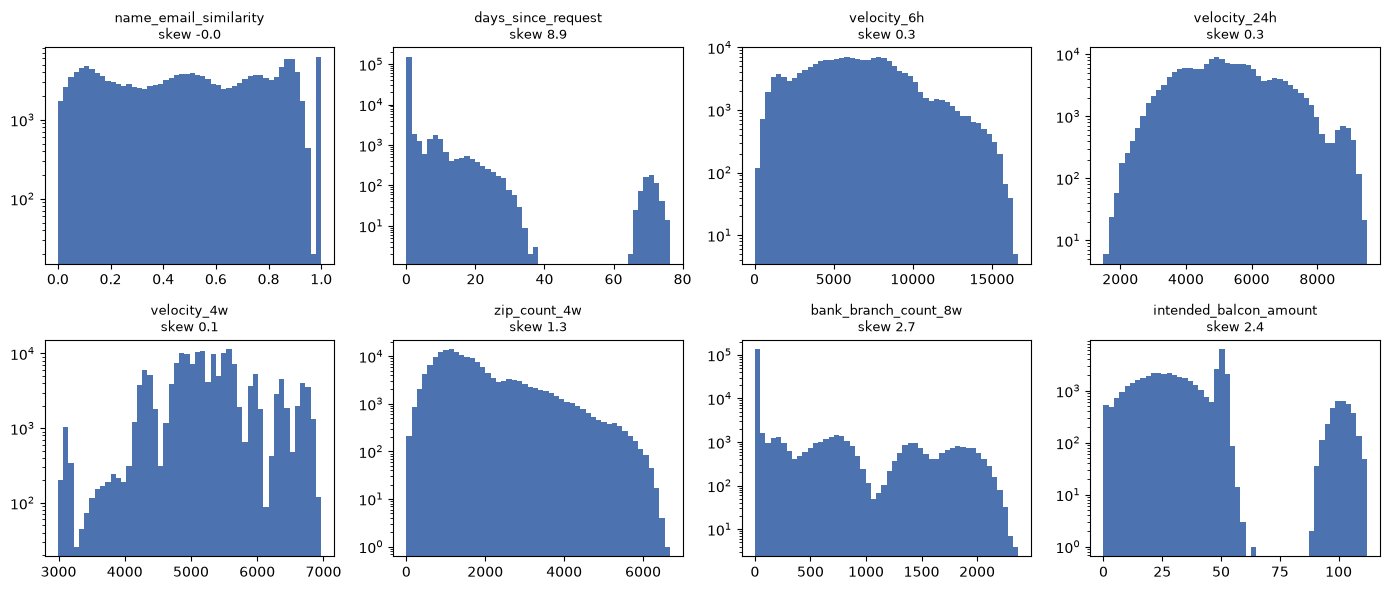

  [fig] outputs/modelling/eda/01_application_skew.png


In [2]:
header("1. APPLICATION TABLE (input to Phase 2 cleaning)")

acc = con.execute(f"SELECT * FROM accounts WHERE open_month IN ({months_sql})").df()
lab = labels(OUT, months=TRAIN, profile=True)
acc = acc.merge(lab, on=["account_id", "open_month"], how="left", validate="1:1")
acc["group"] = np.where(acc["is_launderer"] == 0, "normal",
                        np.where(acc["profile"] == "fake", "fake", "real mule"))
y = acc["is_launderer"].to_numpy()
feat_cols = [c for c in acc.columns if c not in ("account_id", "open_month", "open_day", "is_launderer", "profile", "group")]
num_cols = acc[feat_cols].select_dtypes("number").columns.tolist()
cat_cols = [c for c in feat_cols if c not in num_cols]

log(f"accounts in months {TRAIN}: {len(acc):,}; launderers {int(y.sum()):,} ({y.mean():.3%}); "
    f"by type: {acc.loc[acc.is_launderer == 1, 'profile'].value_counts().to_dict()}")
log(f"{len(num_cols)} numeric and {len(cat_cols)} categorical application columns; true NaN: "
    f"{int(acc[feat_cols].isna().sum().sum())}")

log("\nBAF codes: share of rows with a negative value (BAF writes missing as -1 or a negative amount):")
sent = pd.DataFrame({"share_negative": {c: float((acc[c] < 0).mean()) for c in SENTINEL_COLS + ["credit_risk_score"]}})
sent["min"] = [acc[c].min() for c in sent.index]
sent["note"] = ["missing code -> NaN + flag"] * len(SENTINEL_COLS) + ["real values: the score runs negative; keep as is"]
sent.loc["velocity_6h", "note"] = "9 rows of generator noise at full size -> clip at 0"
table(sent.sort_values("share_negative", ascending=False))

log("categorical levels:")
table(pd.DataFrame({"levels": acc[cat_cols].nunique(),
                    "values": [", ".join(sorted(acc[c].astype(str).unique())) for c in cat_cols]}), index=True)

log("skew of numeric columns (|skew| > 2 -> log1p for logistic regression and the autoencoder):")
sk = acc[num_cols].skew().sort_values(key=np.abs, ascending=False).to_frame("skew")
sk["distinct"] = acc[num_cols].nunique()
table(sk.head(12))

corr = acc[num_cols].corr(method="spearman")
pairs = (corr.where(np.triu(np.ones_like(corr, dtype=bool), 1)).stack()
         .rename("spearman").reset_index().rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs[pairs["spearman"].abs() > 0.5].sort_values("spearman", key=np.abs, ascending=False)
log("application columns with |Spearman| > 0.5 (candidates to drop one of, for logistic regression):")
table(pairs, index=False)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, c in zip(axes.ravel(), SKEWED_COLS):
    v = acc[c].to_numpy(dtype=float)
    ax.hist(v[v >= 0], bins=50, color="#4c72b0")
    ax.set_title(f"{c}\nskew {acc[c].skew():.1f}", fontsize=9)
    ax.set_yscale("log")
savefig(fig, "01_application_skew")

## 2. Application columns vs the label, by hidden type

For every application column: rank AUC and a significance test against `is_launderer` on months 0–4, then the
same AUC for fake accounts alone and for real-customer mules (witting + unwitting) alone. If only fake accounts
separate, the application can buy a head start on fakes only (the "ceiling on earliness" trap in the plan).
A small p-value with a few hundred positives is support for a feature, not proof that it is useful.


2. APPLICATION COLUMNS VS is_launderer (months 0-4), BY HIDDEN TYPE


univariate AUC vs the label (0.5 = none), for all launderers, fake accounts and real-customer mules,
with Mann-Whitney / Welch t (numeric) or chi-square + Cramer's V (categorical). Categorical AUC uses the
level's launderer rate as the score. A small p with 400 positives is support, not proof of usefulness.
| feature                          | kind        |   auc_all |   auc_fake_vs_normal |   auc_real_vs_normal |   mann_whitney_p |   chi2_p |   cramers_v |
|:---------------------------------|:------------|----------:|---------------------:|---------------------:|-----------------:|---------:|------------:|
| housing_status                   | categorical |    0.6422 |               0.6727 |               0.5701 |         nan      |   0.0000 |      0.0332 |
| device_os                        | categorical |    0.6385 |               0.6884 |               0.5205 |         nan      |   0.0000 |      0.0284 |
| keep_alive_session               | numeric     |    0.3984 |               0.

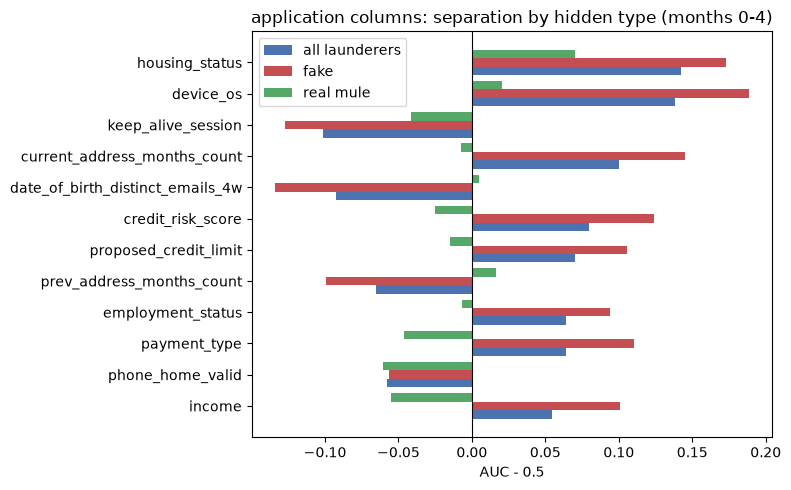

  [fig] outputs/modelling/eda/02_application_auc_by_type.png


In [3]:
header("2. APPLICATION COLUMNS VS is_launderer (months 0-4), BY HIDDEN TYPE")

rows = []
y_fake = (acc["group"] == "fake").to_numpy()
y_real = (acc["group"] == "real mule").to_numpy()
normal = (acc["group"] == "normal").to_numpy()
for c in num_cols:
    x = acc[c].to_numpy(dtype=float)
    pos, neg = x[y == 1], x[y == 0]
    mw = stats.mannwhitneyu(pos, neg, alternative="two-sided").pvalue
    tt = stats.ttest_ind(pos, neg, equal_var=False).pvalue
    rows.append({"feature": c, "kind": "numeric", "auc_all": auc(x, y),
                 "auc_fake_vs_normal": auc(x[y_fake | normal], y_fake[y_fake | normal]),
                 "auc_real_vs_normal": auc(x[y_real | normal], y_real[y_real | normal]),
                 "mann_whitney_p": mw, "welch_t_p": tt, "chi2_p": np.nan, "cramers_v": np.nan,
                 "mean_launderer": pos.mean(), "mean_normal": neg.mean()})


def info_gain(ct: pd.DataFrame) -> float:
    """Information gain of the label from a categorical column (entropy in bits)."""
    p = ct.to_numpy(dtype=float)
    py = p.sum(0) / p.sum()
    h = lambda q: -np.nansum(q * np.log2(np.where(q > 0, q, 1)))
    cond = sum((row.sum() / p.sum()) * h(row / row.sum()) for row in p if row.sum() > 0)
    return h(py) - cond


for c in cat_cols:
    ct = pd.crosstab(acc[c], acc["is_launderer"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.to_numpy().sum() * (min(ct.shape) - 1)))
    rate = acc.groupby(c)["is_launderer"].mean()
    rows.append({"feature": c, "kind": "categorical", "auc_all": auc(acc[c].map(rate), y),
                 "auc_fake_vs_normal": auc(acc[c].map(rate)[y_fake | normal], y_fake[y_fake | normal]),
                 "auc_real_vs_normal": auc(acc[c].map(rate)[y_real | normal], y_real[y_real | normal]),
                 "mann_whitney_p": np.nan, "welch_t_p": np.nan, "chi2_p": p, "cramers_v": v,
                 "info_gain_bits": info_gain(ct), "mean_launderer": np.nan, "mean_normal": np.nan})

uni = pd.DataFrame(rows)
uni["separation"] = (uni["auc_all"] - 0.5).abs()
uni = uni.sort_values("separation", ascending=False)
uni.to_csv(REPORT / "univariate_tests.csv", index=False)
log("univariate AUC vs the label (0.5 = none), for all launderers, fake accounts and real-customer mules,")
log("with Mann-Whitney / Welch t (numeric) or chi-square + Cramer's V (categorical). Categorical AUC uses the")
log("level's launderer rate as the score. A small p with 400 positives is support, not proof of usefulness.")
show = ["feature", "kind", "auc_all", "auc_fake_vs_normal", "auc_real_vs_normal", "mann_whitney_p", "chi2_p", "cramers_v"]
table(uni[show].head(16), index=False)
sig = uni[(uni["mann_whitney_p"] < 0.01) | (uni["chi2_p"] < 0.01)]
log(f"{len(sig)} of {len(uni)} columns significant at p < 0.01 against all launderers; "
    f"columns with |AUC-0.5| >= 0.05 for real-customer mules: "
    f"{uni.loc[(uni['auc_real_vs_normal'] - 0.5).abs() >= 0.05, 'feature'].tolist()}")
log("  -> if that last list is empty or short, real-customer mules are indistinguishable at opening (the")
log("     'ceiling on earliness' trap): the application can only buy a head start on fake accounts.")

top = uni.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(top))
for k, (col, lab_, colr) in enumerate([("auc_all", "all launderers", "#4c72b0"), ("auc_fake_vs_normal", "fake", "#c44e52"),
                                       ("auc_real_vs_normal", "real mule", "#55a868")]):
    ax.barh(yy + (k - 1) * 0.27, top[col] - 0.5, height=0.27, label=lab_, color=colr)
ax.set_yticks(yy, top["feature"])
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("AUC - 0.5")
ax.set_title("application columns: separation by hidden type (months 0-4)")
ax.legend()
savefig(fig, "02_application_auc_by_type")

## 3. A week of activity, by week since opening

An account-week panel for weeks 0–26 (the main horizon), built in DuckDB with only rows up to each week's
cut-off (`day <= open_day + 7w + 6`, the clock used by `labels(weeks_since_open=w)`). It holds every candidate
feature of Phase 3: volume, speed (an ASOF join pairs each payment out with the latest payment in), counterparties,
mix, self-vs-past (median and MAD of earlier weeks), peers and income fit.

Three things are read off it: medians per week for launderers vs normal accounts, the **label maturity** curve
(`mule_by_day` counts fake accounts from week 0, `started_by_day` only once laundering has begun), and the
**closure footprint**: every open account has a weekly card row, so a week with no rows means the bank closed the
account, and only confirmed launderers are closed. Weeks after a closure are a label giveaway a live model never
sees, so Phase 3/4 must drop them from training.


3. A WEEK OF ACTIVITY, BY WEEK SINCE OPENING (weeks 0-26) + LABEL MATURITY


account-week panel for months (0, 1, 2, 3, 4), weeks 0-26: 4,450,113 rows in 20s
medians per account-week, launderers (1) vs normal (0), weeks 0, 1, 4, 8, 12, 26:
|         |         n |   rows_med |   in_med |   out_med |   payers_avg |   payees_med |   cash_avg |   internal_avg |   abroad_avg |   new_payer_avg |   out_24h_avg |
|:--------|----------:|-----------:|---------:|----------:|-------------:|-------------:|-----------:|---------------:|-------------:|----------------:|--------------:|
| (0, 0)  | 164364.00 |       6.00 |    30.44 |    662.59 |         0.63 |         3.00 |       0.08 |           0.01 |         0.00 |            1.00 |          0.56 |
| (0, 1)  |    455.00 |       5.00 |     0.00 |    717.53 |         0.60 |         3.00 |       0.07 |           0.01 |         0.00 |            1.00 |          0.71 |
| (1, 0)  | 164364.00 |       6.00 |    32.39 |    662.61 |         0.63 |         3.00 |       0.08 |           0.01 |         0.00 |            0.78 |         


activity that stops (weeks 0-77): accounts whose last active week is before week 77, and zero-activity weeks
|   is_launderer |   accounts |   stopped_before_week_77 |   zero_activity_weeks |   account_weeks |
|---------------:|-----------:|-------------------------:|----------------------:|----------------:|
|              0 |     164364 |                        1 |                    82 |        12820392 |
|              1 |        455 |                      116 |                  6003 |           35490 |

  -> every open account has at least a weekly card row, so a week with no rows means the account is closed,
     and in this data only the bank's rules close accounts, only after a confirmed (true) alert. Weeks after a
     closure are therefore a label giveaway that a live model never sees (the harness removes closed accounts
     from the pool as caught). Phase 3/4 must drop account-weeks after closure from TRAINING; the screen below
     already leaves them out (rows with n_row


label maturity on training accounts (2s): launderers labelled under each label, by week
|   week |   mule_by_day |   started_by_day |   is_launderer |
|-------:|--------------:|-----------------:|---------------:|
|      0 |           320 |                0 |            455 |
|      1 |           322 |                2 |            455 |
|      4 |           332 |               12 |            455 |
|      8 |           340 |               32 |            455 |
|     12 |           344 |              176 |            455 |
|     17 |           348 |              348 |            455 |
|     26 |           361 |              361 |            455 |
|     39 |           379 |              379 |            455 |
|     52 |           401 |              401 |            455 |
|     78 |           455 |              455 |            455 |



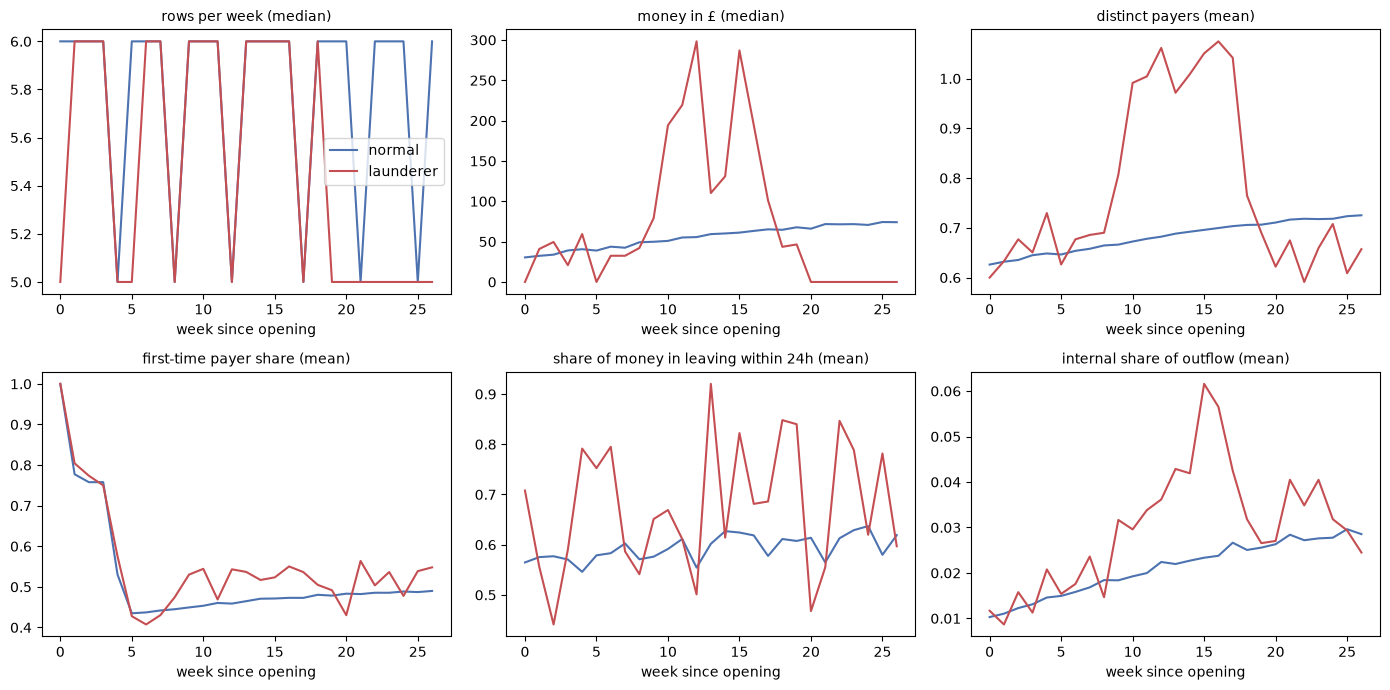

  [fig] outputs/modelling/eda/03_weekly_activity_by_group.png


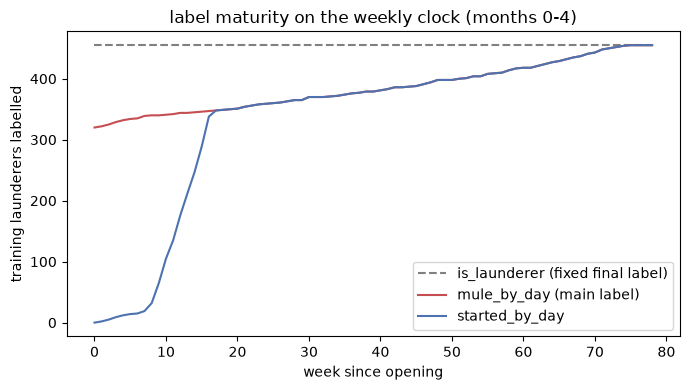

  [fig] outputs/modelling/eda/04_label_maturity.png


In [4]:
header("3. A WEEK OF ACTIVITY, BY WEEK SINCE OPENING (weeks 0-26) + LABEL MATURITY")

t = time.time()
PANEL = f"""
WITH acc AS (
    SELECT account_id, open_day, income, customer_age FROM accounts WHERE open_month IN ({months_sql})),
t AS (
    SELECT x.account_id, x.direction, x.counterparty_id, x.amount, x.payment_type, x.receiver_bank_location,
           (x.day - a.open_day) // 7 AS w,
           x.day * 86400 + CAST(substr(x.time, 1, 2) AS INT) * 3600 + CAST(substr(x.time, 4, 2) AS INT) * 60
               + CAST(substr(x.time, 7, 2) AS INT) AS ts,
           CAST(substr(x.time, 1, 2) AS INT) < 6 AS night,
           row_number() OVER (PARTITION BY x.account_id, x.counterparty_id ORDER BY x.day, x.time) AS nth_with_cp
    FROM transactions x JOIN acc a USING (account_id)
    WHERE x.day <= a.open_day + 7 * {MAX_WEEK} + 6),
ins AS (SELECT account_id, ts FROM t WHERE direction = 'in'),
outs AS (
    SELECT o.account_id, o.w, o.amount, o.ts - i.ts AS delay
    FROM (SELECT account_id, w, amount, ts FROM t WHERE direction = 'out') o
    ASOF LEFT JOIN ins i ON o.account_id = i.account_id AND o.ts >= i.ts),
speed AS (
    SELECT account_id, w,
           coalesce(sum(amount) FILTER (WHERE delay <= 3600), 0)  AS out_1h,
           coalesce(sum(amount) FILTER (WHERE delay <= 86400), 0) AS out_24h,
           median(delay) / 60.0 AS med_delay_min
    FROM outs GROUP BY 1, 2),
wk AS (
    SELECT account_id, w,
           count(*) AS n_rows,
           coalesce(sum(amount) FILTER (WHERE direction = 'in'), 0)  AS money_in,
           coalesce(sum(amount) FILTER (WHERE direction = 'out'), 0) AS money_out,
           coalesce(max(amount) FILTER (WHERE direction = 'in'), 0)  AS max_in,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'in' AND counterparty_id <> 'CASH') AS n_payers,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'out' AND counterparty_id NOT IN ('CASH', 'CARD_MERCHANTS')) AS n_payees,
           count(DISTINCT counterparty_id) FILTER (WHERE direction = 'in' AND counterparty_id <> 'CASH' AND nth_with_cp = 1) AS n_new_payers,
           avg(CASE WHEN payment_type LIKE 'Cash%' THEN 1 ELSE 0 END) AS cash_share,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND counterparty_id LIKE 'A%'), 0) AS internal_out,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND receiver_bank_location <> 'UK'), 0) AS abroad_out,
           coalesce(sum(amount) FILTER (WHERE direction = 'out' AND receiver_bank_location IN ('{"', '".join(HIGH_RISK)}')), 0) AS hr_out,
           avg(CASE WHEN night THEN 1 ELSE 0 END) AS night_share
    FROM t GROUP BY 1, 2),
grid AS (SELECT account_id, open_day, income, customer_age, unnest(range(0, {MAX_WEEK + 1})) AS w FROM acc),
g AS (
    SELECT grid.account_id, grid.w, grid.income, grid.customer_age,
           coalesce(n_rows, 0) n_rows, coalesce(money_in, 0) money_in, coalesce(money_out, 0) money_out,
           coalesce(max_in, 0) max_in, coalesce(n_payers, 0) n_payers, coalesce(n_payees, 0) n_payees,
           coalesce(n_new_payers, 0) n_new_payers, cash_share, coalesce(internal_out, 0) internal_out,
           coalesce(abroad_out, 0) abroad_out, coalesce(hr_out, 0) hr_out, night_share,
           coalesce(out_1h, 0) out_1h, coalesce(out_24h, 0) out_24h, med_delay_min
    FROM grid LEFT JOIN wk USING (account_id, w) LEFT JOIN speed USING (account_id, w))
SELECT *,
    n_new_payers / nullif(n_payers, 0)                                   AS new_payer_share,
    least(money_out, money_in) / nullif(money_in, 0)                     AS passthrough_wk,
    out_1h / nullif(money_in, 0)                                         AS out_1h_share,
    out_24h / nullif(money_in, 0)                                        AS out_24h_share,
    internal_out / nullif(money_out, 0)                                  AS internal_share,
    abroad_out / nullif(money_out, 0)                                    AS abroad_share,
    hr_out / nullif(money_out, 0)                                        AS hr_share,
    sum(money_in) OVER (PARTITION BY account_id ORDER BY w)              AS money_in_cum,
    sum(n_rows)   OVER (PARTITION BY account_id ORDER BY w)              AS n_rows_cum,
    (money_in - median(money_in) OVER past) / nullif(mad(money_in) OVER past, 0) AS self_vs_past_in,
    (n_payers - median(n_payers) OVER past) / nullif(mad(n_payers) OVER past, 0) AS self_vs_past_payers,
    count(*) OVER past                                                   AS n_past_weeks,
    money_in / nullif(median(money_in) OVER (PARTITION BY income, customer_age, w), 0) AS peer_ratio_in,
    money_in / nullif(median(money_in) OVER (PARTITION BY income, w), 0)               AS income_fit_in
FROM g
WINDOW past AS (PARTITION BY account_id ORDER BY w ROWS BETWEEN UNBOUNDED PRECEDING AND 1 PRECEDING)
"""
con.execute(f"CREATE OR REPLACE TABLE panel AS {PANEL}")
# self-vs-past needs at least 4 earlier weeks, as in the plan
con.execute("UPDATE panel SET self_vs_past_in = NULL, self_vs_past_payers = NULL WHERE n_past_weeks < 4")
n_panel = con.execute("SELECT count(*) FROM panel").fetchone()[0]
log(f"account-week panel for months {TRAIN}, weeks 0-{MAX_WEEK}: {n_panel:,} rows in {time.time() - t:.0f}s")

con.register("lab", lab[["account_id", "is_launderer", "profile"]])
by_week = con.execute("""
    SELECT w, l.is_launderer,
           count(*) n, median(n_rows) rows_med, median(money_in) in_med, median(money_out) out_med,
           avg(n_payers) payers_avg, median(n_payees) payees_med, avg(cash_share) cash_avg,
           avg(internal_share) internal_avg, avg(abroad_share) abroad_avg, avg(new_payer_share) new_payer_avg,
           avg(out_24h_share) out_24h_avg
    FROM panel p JOIN lab l USING (account_id) GROUP BY 1, 2 ORDER BY 1, 2""").df()
log("medians per account-week, launderers (1) vs normal (0), weeks 0, 1, 4, 8, 12, 26:")
table(by_week[by_week["w"].isin([0, 1, 4, 8, 12, 26])].set_index(["w", "is_launderer"]), floatfmt=".2f")
log("  -> before any laundering starts, launderers' weeks should look like everyone else's: the simulator gives")
log("     every profile the same normal life. Differences in early weeks come from the application side only.")

# 3b. activity that stops: the footprint of the bank's closures in the public data
stop = con.execute(f"""
    WITH acc AS (SELECT account_id, open_day FROM accounts WHERE open_month IN ({months_sql})),
    grid AS (SELECT account_id, unnest(range(0, 78)) AS w FROM acc),       -- week 78 is partial (2 days), left out
    wk AS (SELECT a.account_id, (x.day - a.open_day) // 7 AS w, count(*) n
           FROM transactions x JOIN acc a USING (account_id) GROUP BY 1, 2),
    g AS (SELECT grid.account_id, grid.w, coalesce(n, 0) n FROM grid LEFT JOIN wk USING (account_id, w)),
    la AS (SELECT account_id, max(w) FILTER (WHERE n > 0) AS last_active_w FROM g GROUP BY 1)
    SELECT l.is_launderer, count(*) AS accounts,
           sum(CASE WHEN last_active_w < 77 THEN 1 ELSE 0 END) AS stopped_before_week_77,
           (SELECT sum(CASE WHEN n = 0 THEN 1 ELSE 0 END) FROM g JOIN lab l2 USING (account_id)
             WHERE l2.is_launderer = l.is_launderer) AS zero_activity_weeks,
           (SELECT count(*) FROM g JOIN lab l2 USING (account_id) WHERE l2.is_launderer = l.is_launderer) AS account_weeks
    FROM la JOIN lab l USING (account_id) GROUP BY 1 ORDER BY 1""").df().set_index("is_launderer")
log("\nactivity that stops (weeks 0-77): accounts whose last active week is before week 77, and zero-activity weeks")
table(stop, floatfmt=".0f")
log("  -> every open account has at least a weekly card row, so a week with no rows means the account is closed,")
log("     and in this data only the bank's rules close accounts, only after a confirmed (true) alert. Weeks after a")
log("     closure are therefore a label giveaway that a live model never sees (the harness removes closed accounts")
log("     from the pool as caught). Phase 3/4 must drop account-weeks after closure from TRAINING; the screen below")
log("     already leaves them out (rows with n_rows = 0). Decision needed: let labels() return 'open at week w' for")
log("     months 0-5, since a bank knows which accounts it closed.")

# label maturity on the weekly clock, weeks 0-78 (one labels() call per week; the only hidden columns used)
t = time.time()
mat = []
first_start = pd.Series(np.nan, index=lab["account_id"])
for w in range(0, 79):
    lw = labels(OUT, months=TRAIN, weeks_since_open=w)
    mat.append({"week": w, "mule_by_day": int(lw["mule_by_day"].sum()), "started_by_day": int(lw["started_by_day"].sum()),
                "is_launderer": int(lw["is_launderer"].sum())})
    started = lw.loc[lw["started_by_day"] == 1, "account_id"]
    first_start.loc[first_start.index.isin(started) & first_start.isna()] = w
mat = pd.DataFrame(mat).set_index("week")
log(f"\nlabel maturity on training accounts ({time.time() - t:.0f}s): launderers labelled under each label, by week")
table(mat.loc[[0, 1, 4, 8, 12, 17, 26, 39, 52, 78]], floatfmt=".0f")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (col, title) in zip(axes.ravel(), [("rows_med", "rows per week (median)"), ("in_med", "money in £ (median)"),
                                           ("payers_avg", "distinct payers (mean)"), ("new_payer_avg", "first-time payer share (mean)"),
                                           ("out_24h_avg", "share of money in leaving within 24h (mean)"),
                                           ("internal_avg", "internal share of outflow (mean)")]):
    for lab_val, colr, name in [(0, "#4c72b0", "normal"), (1, "#c44e52", "launderer")]:
        s = by_week[by_week["is_launderer"] == lab_val]
        ax.plot(s["w"], s[col], color=colr, label=name)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("week since opening")
axes[0, 0].legend()
savefig(fig, "03_weekly_activity_by_group")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(mat.index, mat["is_launderer"], color="grey", ls="--", label="is_launderer (fixed final label)")
ax.plot(mat.index, mat["mule_by_day"], color="#c44e52", label="mule_by_day (main label)")
ax.plot(mat.index, mat["started_by_day"], color="#4c72b0", label="started_by_day")
ax.set_xlabel("week since opening")
ax.set_ylabel("training launderers labelled")
ax.set_title("label maturity on the weekly clock (months 0-4)")
ax.legend()
savefig(fig, "04_label_maturity")

## 4. When laundering starts on the weekly clock

The first week in which each training launderer's `started_by_day` turns 1, by hidden type. Weeks before that
can only be won on application data (fake accounts) or not at all (real-customer mules).


4. WHEN LAUNDERING STARTS ON THE WEEKLY CLOCK (training launderers)
| profile   |   count |   min |   10% |   50% |   90% |   max |
|:----------|--------:|------:|------:|------:|------:|------:|
| fake      |     320 |     8 |     9 |    13 |    16 |    17 |
| unwitting |      69 |     1 |     4 |    42 |    69 |    74 |
| witting   |      66 |     1 |    13 |    47 |    70 |    75 |

launderers whose start lies inside the main horizon (week <= 26): 361 of 455; by type: {'fake': 320, 'unwitting': 25, 'witting': 16}
  -> weeks before an account's start week can only be won on application data (fake accounts) or not at all
     (real-customer mules). Report 'days earlier' separately for the two.


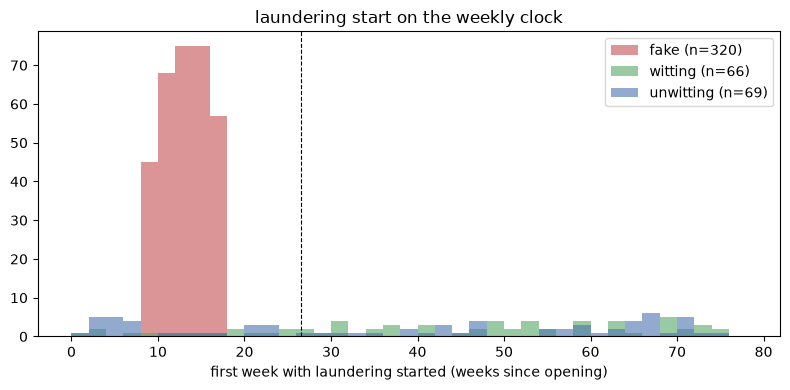

  [fig] outputs/modelling/eda/05_start_week_by_type.png


In [5]:
header("4. WHEN LAUNDERING STARTS ON THE WEEKLY CLOCK (training launderers)")

fs = first_start.dropna().rename("first_week").to_frame().join(lab.set_index("account_id")["profile"])
q = fs.groupby("profile")["first_week"].describe(percentiles=[.1, .5, .9])[["count", "min", "10%", "50%", "90%", "max"]]
table(q, floatfmt=".0f")
log(f"launderers whose start lies inside the main horizon (week <= {MAX_WEEK}): "
    f"{int((fs['first_week'] <= MAX_WEEK).sum())} of {len(fs)}; by type: "
    f"{fs[fs['first_week'] <= MAX_WEEK].groupby('profile').size().to_dict()}")
log("  -> weeks before an account's start week can only be won on application data (fake accounts) or not at all")
log("     (real-customer mules). Report 'days earlier' separately for the two.")

fig, ax = plt.subplots(figsize=(8, 4))
for prof, colr in [("fake", "#c44e52"), ("witting", "#55a868"), ("unwitting", "#4c72b0")]:
    v = fs.loc[fs["profile"] == prof, "first_week"]
    ax.hist(v, bins=np.arange(0, 80, 2), alpha=0.6, color=colr, label=f"{prof} (n={len(v)})")
ax.axvline(MAX_WEEK + 0.5, color="k", ls="--", lw=0.8)
ax.set_xlabel("first week with laundering started (weeks since opening)")
ax.set_title("laundering start on the weekly clock")
ax.legend()
savefig(fig, "05_start_week_by_type")

## 5. Candidate feature screen at weeks 4, 8, 12 and 26

Rank AUC of every candidate feature at four weeks since opening, against `mule_by_day` (the main label) and
against `started_by_day` (accounts whose laundering has begun), also split by hidden type. Only account-weeks
with activity are used (closed accounts left out), and an AUC with fewer than 20 positives is shown as NaN.
The correlation matrix at week 12 shows which candidates say the same thing.


5. CANDIDATE FEATURE SCREEN AT WEEKS 4, 8, 12, 26 (months 0-4)


Account-weeks with activity only (closed accounts left out); AUCs with fewer than 20 positives shown as NaN.
AUC against mule_by_day (main label) by week since opening; 0.5 = no signal:
| feature             |      4 |      8 |     12 |     26 |   max_sep |
|:--------------------|-------:|-------:|-------:|-------:|----------:|
| n_rows_cum          | 0.4945 | 0.5057 | 0.6079 | 0.7087 |    0.2087 |
| money_in_cum        | 0.5787 | 0.5909 | 0.6505 | 0.6689 |    0.1689 |
| self_vs_past_in     | 0.4976 | 0.4981 | 0.4680 | 0.3558 |    0.1442 |
| money_out           | 0.5674 | 0.5721 | 0.6431 | 0.5704 |    0.1431 |
| self_vs_past_payers | 0.4968 | 0.5007 | 0.4684 | 0.3594 |    0.1406 |
| med_delay_min       | 0.5053 | 0.4787 | 0.3722 | 0.4649 |    0.1278 |
| n_rows              | 0.5018 | 0.5031 | 0.6127 | 0.5141 |    0.1127 |
| peer_ratio_in       | 0.5313 | 0.5031 | 0.5978 | 0.5163 |    0.0978 |
| n_payers            | 0.5048 | 0.5062 | 0.5978 | 0.5224 |    0.0978 |
| income_fit_in       

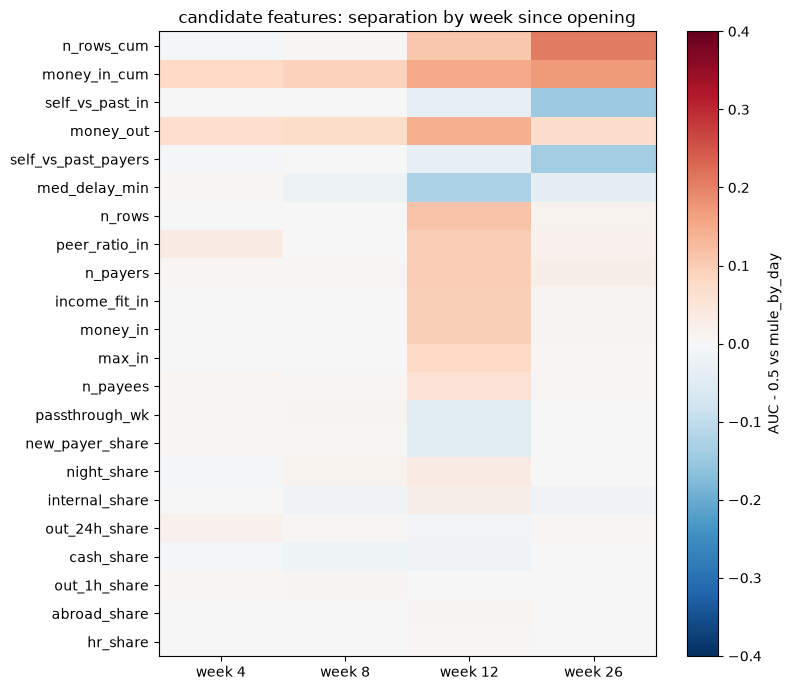

  [fig] outputs/modelling/eda/06_feature_screen_heatmap.png


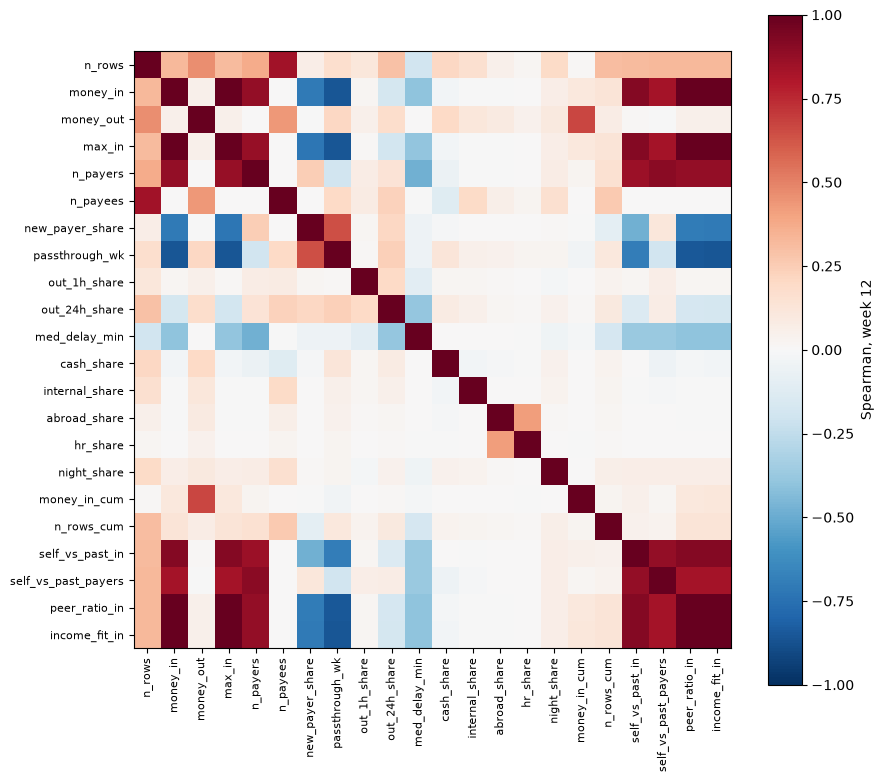

  [fig] outputs/modelling/eda/07_feature_correlation_week12.png


In [6]:
header("5. CANDIDATE FEATURE SCREEN AT WEEKS 4, 8, 12, 26 (months 0-4)")

CANDIDATES = ["n_rows", "money_in", "money_out", "max_in", "n_payers", "n_payees", "new_payer_share",
              "passthrough_wk", "out_1h_share", "out_24h_share", "med_delay_min", "cash_share", "internal_share",
              "abroad_share", "hr_share", "night_share", "money_in_cum", "n_rows_cum",
              "self_vs_past_in", "self_vs_past_payers", "peer_ratio_in", "income_fit_in"]
screen = []
corr_at_12 = None
for W in SCREEN_WEEKS:
    pw = con.execute(f"SELECT * FROM panel WHERE w = {W}").df()
    lw = labels(OUT, months=TRAIN, weeks_since_open=W, profile=True)
    pw = pw.merge(lw, on="account_id", how="inner")
    pw = pw[pw["n_rows"] > 0].reset_index(drop=True)          # open accounts only (see section 3)
    grp = np.where(pw["is_launderer"] == 0, "normal", np.where(pw["profile"] == "fake", "fake", "real mule"))
    nrm = grp == "normal"
    for c in CANDIDATES:
        x = pw[c].to_numpy(dtype=float)
        started = pw["started_by_day"].to_numpy() == 1
        rec = {"week": W, "feature": c, "nonnull_share": float(np.isfinite(x).mean()),
               "auc_mule_by_day": auc(x, pw["mule_by_day"]),
               "auc_started_by_day": auc(x[started | nrm], started[started | nrm]),
               "auc_fake_vs_normal": auc(x[(grp == "fake") | nrm], (grp == "fake")[(grp == "fake") | nrm]),
               "auc_real_started_vs_normal": auc(x[((grp == "real mule") & started) | nrm],
                                                 ((grp == "real mule") & started)[((grp == "real mule") & started) | nrm]),
               "n_mule": int(pw["mule_by_day"].sum()), "n_started": int(started.sum()),
               "n_real_started": int(((grp == "real mule") & started).sum())}
        for k, npos in [("auc_mule_by_day", rec["n_mule"]), ("auc_started_by_day", rec["n_started"]),
                        ("auc_fake_vs_normal", int((grp == "fake").sum())), ("auc_real_started_vs_normal", rec["n_real_started"])]:
            if npos < MIN_POS:
                rec[k] = np.nan                                    # too few positives for the AUC to mean anything
        screen.append(rec)
    if W == 12:
        corr_at_12 = pw[CANDIDATES].corr(method="spearman")
screen = pd.DataFrame(screen)
screen.to_csv(REPORT / "feature_screen.csv", index=False)

log(f"Account-weeks with activity only (closed accounts left out); AUCs with fewer than {MIN_POS} positives shown as NaN.")
log("AUC against mule_by_day (main label) by week since opening; 0.5 = no signal:")
piv = screen.pivot(index="feature", columns="week", values="auc_mule_by_day")
piv["max_sep"] = (piv - 0.5).abs().max(axis=1)
table(piv.sort_values("max_sep", ascending=False))
log("AUC against started_by_day (accounts whose laundering has started vs normal):")
piv2 = screen.pivot(index="feature", columns="week", values="auc_started_by_day")
log(f"launderers started by week: {screen.groupby('week')['n_started'].first().to_dict()} "
    f"(real-customer mules: {screen.groupby('week')['n_real_started'].first().to_dict()})")
table(piv2.loc[piv.sort_values("max_sep", ascending=False).index])
log("  -> mule_by_day counts fake accounts from week 0 even while their activity is still normal, so activity")
log("     features look weak against it in early weeks by construction. started_by_day shows what activity")
log("     can see once a burst exists; with few starts before week 8, those early AUCs are noisy.")

hi = (corr_at_12.where(np.triu(np.ones_like(corr_at_12, dtype=bool), 1)).stack().rename("spearman").reset_index())
hi = hi[hi["spearman"].abs() > 0.8].sort_values("spearman", key=np.abs, ascending=False)
log("candidate pairs with |Spearman| > 0.8 at week 12 (keep one of each for logistic regression):")
table(hi.rename(columns={"level_0": "a", "level_1": "b"}), index=False)

fig, ax = plt.subplots(figsize=(8, 7))
hm = (piv.drop(columns="max_sep") - 0.5).loc[piv.sort_values("max_sep", ascending=False).index]
im = ax.imshow(hm.to_numpy(), cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(hm.shape[1]), [f"week {w}" for w in hm.columns])
ax.set_yticks(range(hm.shape[0]), hm.index)
fig.colorbar(im, ax=ax, label="AUC - 0.5 vs mule_by_day")
ax.set_title("candidate features: separation by week since opening")
savefig(fig, "06_feature_screen_heatmap")

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr_at_12.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(CANDIDATES)), CANDIDATES, rotation=90, fontsize=8)
ax.set_yticks(range(len(CANDIDATES)), CANDIDATES, fontsize=8)
fig.colorbar(im, ax=ax, label="Spearman, week 12")
savefig(fig, "07_feature_correlation_week12")

## 6. Simulator fingerprints and the homophily test

Each candidate feature and the `configs/sim.yaml` setting it rests on, so the report can say which results
depend on which assumptions (the 42 sensitivity runs test them). Then the L8 homophily test: among the accounts
a training account pays inside our bank, how often is the payee a launderer, for launderers vs normal accounts?
Only edges with both ends in months 0–4 are counted.

In [7]:
header("6. SIMULATOR-FINGERPRINT AUDIT + HOMOPHILY TEST")

FINGERPRINTS = {
    "out_1h_share / out_24h_share / med_delay_min": "laundering.forward_delay_shares (RUSI speed bands); normal accounts have no in->out link at all",
    "passthrough_wk": "laundering.holder_keeps (0-10% kept) and the same R4 logic the rules use",
    "n_payers / new_payer_share": "laundering.shapes senders ('all' = every payment from a new payer); normal.transfers_in_per_month = 1.0",
    "n_payees": "laundering.shapes recipients; normal.transfers_out_per_month",
    "cash_share": "laundering.shapes in_kind cash / half_cash; normal.cash_depositor_share 0.06",
    "internal_share": "networks.internal_pieces_share 0.5 (x2 for layered shapes) vs normal.internal_share_of_transfers 0.10",
    "abroad_share / hr_share": "laundering.abroad_ratio_vs_normal 3.15 x normal.abroad_sender_share 0.07; high_risk_share_of_cross_border",
    "money_in / max_in / self_vs_past_in": "laundering.out_transfer_mean GBP 532 x shape amount_rel vs income-scaled normal amounts",
    "peer_ratio_in / income_fit_in": "normal money in scales with BAF income (ONS fifths); laundering amounts do not -> the ratio is partly a fingerprint",
    "night_share": "normal.hour_weights only; laundering uses the same hour weights, so no signal is expected",
    "application columns": "profiles.in_window_mix (73% of launderers are BAF fraud rows): the whole application signal rests on this one assumption",
}
fp = pd.DataFrame({"feature(s)": list(FINGERPRINTS), "rests on (configs/sim.yaml)": list(FINGERPRINTS.values())})
log("each candidate feature and the simulator setting it rests on; the 42 sensitivity runs test these settings:")
table(fp, index=False)

# homophily: among the accounts a training account pays inside our bank, how many are launderers?
hom = con.execute(f"""
    WITH acc AS (SELECT account_id FROM accounts WHERE open_month IN ({months_sql})),
    e AS (SELECT DISTINCT x.account_id AS src, x.counterparty_id AS dst
          FROM transactions x JOIN acc USING (account_id)
          WHERE x.direction = 'out' AND x.counterparty_id LIKE 'A%'),
    e2 AS (SELECT e.src, e.dst, ls.is_launderer AS src_l, ld.is_launderer AS dst_l
           FROM e JOIN lab ls ON ls.account_id = e.src JOIN lab ld ON ld.account_id = e.dst)
    SELECT src_l, count(*) AS edges, count(DISTINCT src) AS accounts, avg(dst_l) AS launderer_share_of_payees
    FROM e2 GROUP BY 1 ORDER BY 1""").df()
base = float(lab["is_launderer"].mean())
table(hom.set_index("src_l"))
share_l = hom.loc[hom["src_l"] == 1, "launderer_share_of_payees"].iloc[0] if (hom["src_l"] == 1).any() else np.nan
log(f"base launderer rate in months 0-4: {base:.4%}. A launderer's internal payees are launderers "
    f"{share_l:.2%} of the time ({share_l / base:.0f}x the base rate); a normal account's "
    f"{hom.loc[hom['src_l'] == 0, 'launderer_share_of_payees'].iloc[0]:.3%}.")
log("  -> this is the L8 homophily test. A ratio well above 1 says the chains and the big network leave a trace in")
log("     the public transactions, so graph features (Phase 6) have something to find. Only edges with both ends")
log("     in months 0-4 are counted, so no test-month account enters the test.")


6. SIMULATOR-FINGERPRINT AUDIT + HOMOPHILY TEST
each candidate feature and the simulator setting it rests on; the 42 sensitivity runs test these settings:
| feature(s)                                   | rests on (configs/sim.yaml)                                                                                              |
|:---------------------------------------------|:-------------------------------------------------------------------------------------------------------------------------|
| out_1h_share / out_24h_share / med_delay_min | laundering.forward_delay_shares (RUSI speed bands); normal accounts have no in->out link at all                          |
| passthrough_wk                               | laundering.holder_keeps (0-10% kept) and the same R4 logic the rules use                                                 |
| n_payers / new_payer_share                   | laundering.shapes senders ('all' = every payment from a new payer); normal.transfers_in_per_month = 1.0    

|   src_l |        edges |    accounts |   launderer_share_of_payees |
|--------:|-------------:|------------:|----------------------------:|
|       0 | 1254238.0000 | 164270.0000 |                      0.0023 |
|       1 |    2994.0000 |    433.0000 |                      0.0544 |

base launderer rate in months 0-4: 0.2761%. A launderer's internal payees are launderers 5.44% of the time (20x the base rate); a normal account's 0.226%.
  -> this is the L8 homophily test. A ratio well above 1 says the chains and the big network leave a trace in
     the public transactions, so graph features (Phase 6) have something to find. Only edges with both ends
     in months 0-4 are counted, so no test-month account enters the test.


## 7. Benford's law on all amounts

A realism check for the professor's comment 1, never a feature: each launderer has 3–15 laundering payments,
far too few for Benford. Nigrini's mean absolute deviation on the first digit is the usual yardstick.


7. BENFORD'S LAW ON ALL AMOUNTS (realism check for comment 1; not a feature)


|   d |             n |   observed |   benford |
|----:|--------------:|-----------:|----------:|
|   1 | 23179887.0000 |     0.3176 |    0.3010 |
|   2 | 13639835.0000 |     0.1869 |    0.1761 |
|   3 |  9445403.0000 |     0.1294 |    0.1249 |
|   4 |  6629732.0000 |     0.0908 |    0.0969 |
|   5 |  5265947.0000 |     0.0722 |    0.0792 |
|   6 |  4408183.0000 |     0.0604 |    0.0669 |
|   7 |  3819446.0000 |     0.0523 |    0.0580 |
|   8 |  3438397.0000 |     0.0471 |    0.0512 |
|   9 |  3151946.0000 |     0.0432 |    0.0458 |

rows 72,978,776; chi-square 320,829 (any large sample rejects); Nigrini MAD 0.0071 (first digit: < 0.006 close, 0.006-0.012 acceptable, 0.012-0.015 marginal, > 0.015 nonconformity)
  -> amounts are lognormal around published medians, so rough conformity is expected; it says the amount
     mix is not absurd, nothing more. Each launderer has 3-15 laundering payments, far too few for Benford.


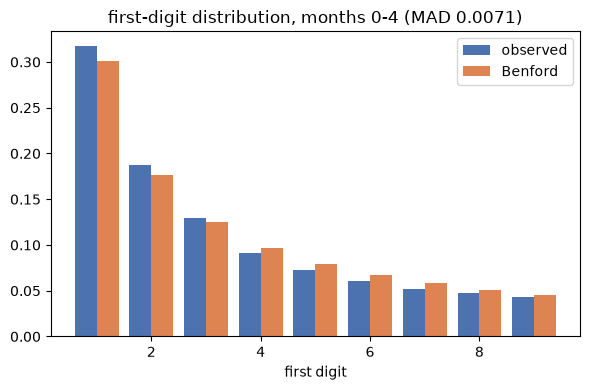

  [fig] outputs/modelling/eda/08_benford.png


In [8]:
header("7. BENFORD'S LAW ON ALL AMOUNTS (realism check for comment 1; not a feature)")

bf = con.execute(f"""
    SELECT CAST(substr(CAST(amount AS VARCHAR), 1, 1) AS INT) AS d, count(*) n
    FROM transactions x JOIN (SELECT account_id FROM accounts WHERE open_month IN ({months_sql})) a USING (account_id)
    WHERE amount >= 1 GROUP BY 1 HAVING d BETWEEN 1 AND 9 ORDER BY 1""").df().set_index("d")
bf["observed"] = bf["n"] / bf["n"].sum()
bf["benford"] = [np.log10(1 + 1 / d) for d in bf.index]
chi2 = float((((bf["observed"] - bf["benford"]) ** 2) / bf["benford"]).sum() * bf["n"].sum())
mad_ = float((bf["observed"] - bf["benford"]).abs().mean())
table(bf, floatfmt=".4f")
log(f"rows {int(bf['n'].sum()):,}; chi-square {chi2:,.0f} (any large sample rejects); Nigrini MAD {mad_:.4f} "
    f"(first digit: < 0.006 close, 0.006-0.012 acceptable, 0.012-0.015 marginal, > 0.015 nonconformity)")
log("  -> amounts are lognormal around published medians, so rough conformity is expected; it says the amount")
log("     mix is not absurd, nothing more. Each launderer has 3-15 laundering payments, far too few for Benford.")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(bf.index - 0.2, bf["observed"], width=0.4, label="observed", color="#4c72b0")
ax.bar(bf.index + 0.2, bf["benford"], width=0.4, label="Benford", color="#dd8452")
ax.set_xlabel("first digit")
ax.set_title(f"first-digit distribution, months 0-4 (MAD {mad_:.4f})")
ax.legend()
savefig(fig, "08_benford")

## 8. Proposed feature list for Phase 3

A keep/drop proposal per candidate from the screen above. The team fixes the list at the Phase 1 gate; the
notes on speed features and rare-event shares say what Phase 3 should change. The last cell writes the report.

In [9]:
header("8. PROPOSED FEATURE LIST FOR PHASE 3 (the team fixes it at the gate)")

best = screen.groupby("feature").agg(best_sep_mule=("auc_mule_by_day", lambda s: (s - 0.5).abs().max()),
                                     best_sep_started=("auc_started_by_day", lambda s: (s - 0.5).abs().max()),
                                     nonnull=("nonnull_share", "min"))
best["proposal"] = np.where((best[["best_sep_mule", "best_sep_started"]].max(axis=1) >= 0.05), "keep",
                            "drop (no signal at any screened week)")
best.loc["night_share", "proposal"] += "; expected: same hour weights for everyone"
best = best.sort_values("best_sep_started", ascending=False)
table(best)
log("Speed features as screened here (out_1h_share, out_24h_share) are swamped by everyday outflows: the ASOF join")
log("pairs every card, direct-debit or cash row with the latest payment in, so normal accounts also 'forward' about")
log("half of their money in within a day. Phase 3 should define them as transfers OUT (ACH, Cross-border) within")
log("1h / 24h after each transfer IN, capped at that payment's amount; med_delay_min already carries the signal.")
log("abroad_share, hr_share and cash_share are rare events at week level (launderers send ~1.6% of transfers abroad);")
log("keep them cumulative rather than weekly if kept at all.")
log("Application columns: keep all 29 after Phase 2 cleaning; LightGBM ignores useless ones and L1 logistic")
log("regression drops them. Candidate pairs above |0.8| correlation: keep one for the logistic model.")
log(f"\ndone in {time.time() - T0:.0f}s")

(REPORT / "report.md").write_text("\n".join(_lines), encoding="utf-8")
print(f"\nreport  -> {REPORT / 'report.md'}\nfigures -> {REPORT}")


8. PROPOSED FEATURE LIST FOR PHASE 3 (the team fixes it at the gate)
| feature             |   best_sep_mule |   best_sep_started |   nonnull | proposal                                       |
|:--------------------|----------------:|-------------------:|----------:|:-----------------------------------------------|
| n_rows_cum          |          0.2087 |             0.3642 |    1.0000 | keep                                           |
| n_rows              |          0.1127 |             0.3045 |    1.0000 | keep                                           |
| med_delay_min       |          0.1278 |             0.2890 |    0.9999 | keep                                           |
| n_payers            |          0.0978 |             0.2580 |    1.0000 | keep                                           |
| money_out           |          0.1431 |             0.2480 |    1.0000 | keep                                           |
| money_in_cum        |          0.1689 |             0.2302 |